## Import

In [1]:
import pandas as pd
import numpy as np
import json

from pathlib import Path

## Load TRAIN

In [2]:
TRAIN_PATH = Path("../data/processed/train.csv")

train_df = pd.read_csv(TRAIN_PATH)

print("Train shape:", train_df.shape)

display(train_df.head())

Train shape: (64000, 8)


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social,dev_status
0,1.000000,0.685714,0.0,delayed,caution,normal,caution,suspect
1,0.705882,0.857143,0.6,delayed,caution,caution,caution,suspect
2,0.294118,0.500000,0.4,caution,delayed,normal,caution,suspect
3,0.235294,0.400000,1.0,delayed,caution,advanced,caution,suspect
4,0.294118,0.585714,0.8,advanced,normal,caution,advanced,normal


## Definisikan fitur KG

In [3]:
feature_columns = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

target_column = "dev_status"

print("Fitur KG:")
for col in feature_columns:
    print("-", col)

print("\nTarget:", target_column)

Fitur KG:
- weight
- height
- age
- gross_motor
- fine_motor_adaptive
- language
- personal_social

Target: dev_status


In [4]:
assert target_column not in feature_columns

print("✅ dev_status tidak digunakan dalam KG.")

✅ dev_status tidak digunakan dalam KG.


## Mapping relasi

In [5]:
relation_mapping = {
    "weight": "has_weight",
    "height": "has_height",
    "age": "has_age",
    "gross_motor": "has_gross_motor",
    "fine_motor_adaptive": "has_fine_motor_adaptive",
    "language": "has_language",
    "personal_social": "has_personal_social"
}

print(relation_mapping)

{'weight': 'has_weight', 'height': 'has_height', 'age': 'has_age', 'gross_motor': 'has_gross_motor', 'fine_motor_adaptive': 'has_fine_motor_adaptive', 'language': 'has_language', 'personal_social': 'has_personal_social'}


## Fungsi membuat entity ID

In [6]:
def format_value(value):
    if pd.isna(value):
        return "unknown"

    if isinstance(value, (int, np.integer)):
        return str(value)

    if isinstance(value, (float, np.floating)):
        return f"{value:.6f}".rstrip("0").rstrip(".")

    return str(value).strip().lower().replace(" ", "_")


def create_tail_entity(column, value):
    value_id = format_value(value)
    return f"{column}_{value_id}"

In [17]:
# Contoh pengujian format_value
test_values = [
    25,
    12.500000,
    " Normal ",
    "Fine Motor Adaptive",
    np.nan
]

for value in test_values:
    print(f"{value} → {format_value(value)}")

25 → 25
12.5 → 12.5
 Normal  → normal
Fine Motor Adaptive → fine_motor_adaptive
nan → unknown


In [19]:
# Contoh pengujian create_tail_entity
test_data = [
    ("weight", 1),
    ("height", 0.685714),
    ("gross_motor", "Normal"),
    ("fine_motor_adaptive", "Fine Motor Adaptive"),
    ("language", np.nan)
]

for column, value in test_data:
    print(f"{column}, {value} → {create_tail_entity(column, value)}")

weight, 1 → weight_1
height, 0.685714 → height_0.685714
gross_motor, Normal → gross_motor_normal
fine_motor_adaptive, Fine Motor Adaptive → fine_motor_adaptive_fine_motor_adaptive
language, nan → language_unknown


## Bangun Triple

In [7]:
triples = []

for idx, row in train_df.reset_index(drop=True).iterrows():

    child_entity = f"child_train_{idx + 1:06d}"

    for column in feature_columns:

        relation = relation_mapping[column]
        tail_entity = create_tail_entity(
            column,
            row[column]
        )

        triples.append({
            "head": child_entity,
            "relation": relation,
            "tail": tail_entity
        })

kg_df = pd.DataFrame(triples)

print("Jumlah triple:", len(kg_df))

display(kg_df.head(20))
display(kg_df.tail(10))

Jumlah triple: 448000


,head,relation,tail
0,child_train_000001,has_weight,weight_1
1,child_train_000001,has_height,height_0.685714
2,child_train_000001,has_age,age_0
3,child_train_000001,has_gross_motor,gross_motor_delayed
4,child_train_000001,has_fine_motor_adaptive,fine_motor_adaptive_caution
5,child_train_000001,has_language,language_normal
6,child_train_000001,has_personal_social,personal_social_caution
7,child_train_000002,has_weight,weight_0.705882
8,child_train_000002,has_height,height_0.857143
9,child_train_000002,has_age,age_0.6


,head,relation,tail
447990,child_train_063999,has_fine_motor_adaptive,fine_motor_adaptive_normal
447991,child_train_063999,has_language,language_normal
447992,child_train_063999,has_personal_social,personal_social_advanced
447993,child_train_064000,has_weight,weight_0.941176
447994,child_train_064000,has_height,height_0.414286
447995,child_train_064000,has_age,age_0
447996,child_train_064000,has_gross_motor,gross_motor_delayed
447997,child_train_064000,has_fine_motor_adaptive,fine_motor_adaptive_advanced
447998,child_train_064000,has_language,language_delayed
447999,child_train_064000,has_personal_social,personal_social_delayed


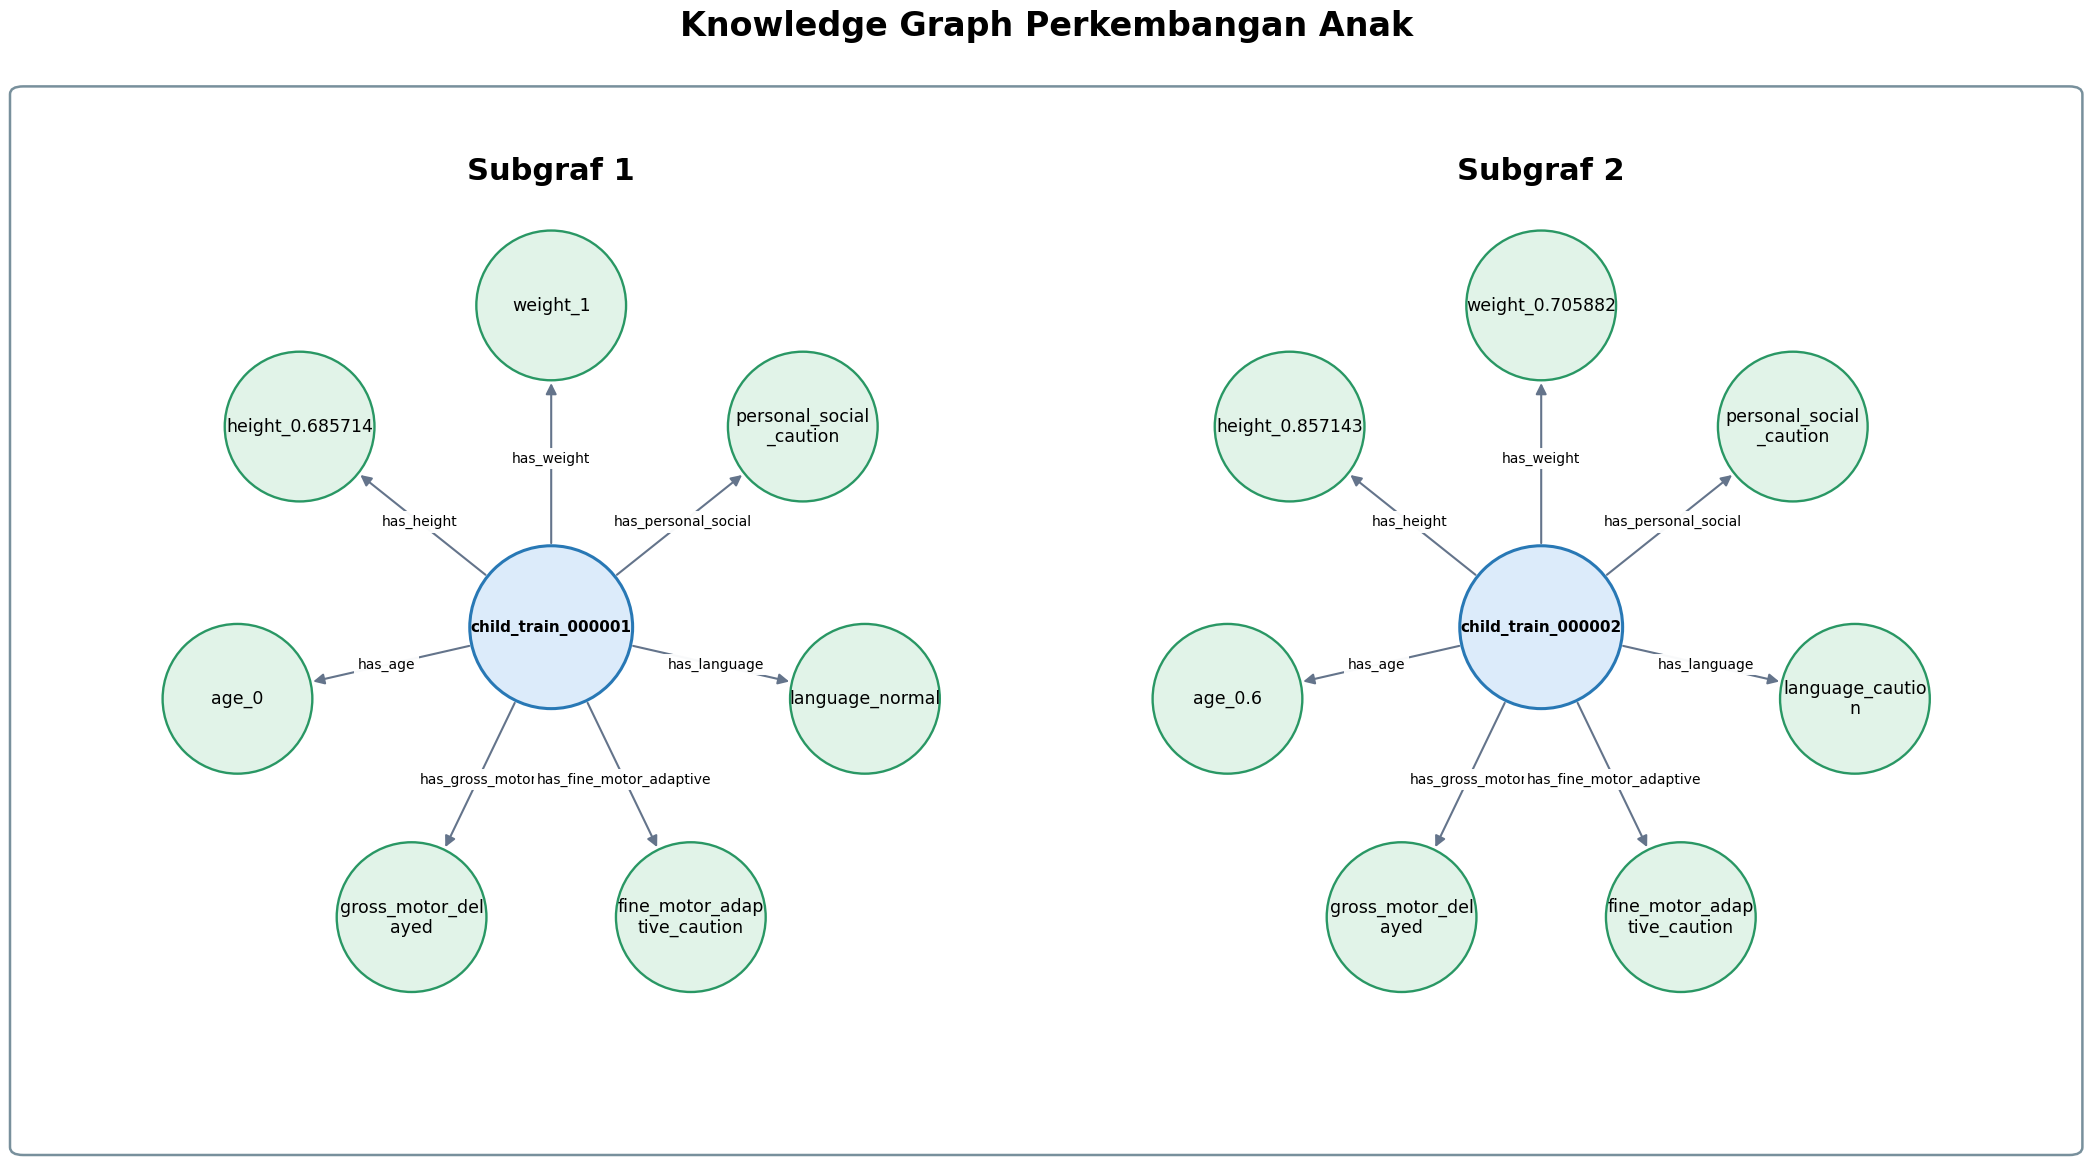

In [8]:

import matplotlib.pyplot as plt
import numpy as np
import textwrap
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Dua contoh data dari data training
sample_indices = [0, 1]
samples = [train_df.iloc[i] for i in sample_indices]

# Pengaturan gambar
fig = plt.figure(figsize=(22, 13))
fig.suptitle(
    "Knowledge Graph Perkembangan Anak",
    fontsize=24, fontweight="bold", y=0.965
)

# Satu bingkai untuk seluruh visualisasi KG
fig.patches.append(FancyBboxPatch(
    (0.035, 0.09), 0.93, 0.81,
    boxstyle="round,pad=0.006",
    transform=fig.transFigure,
    fill=False, edgecolor="#78909C", linewidth=1.8
))

# Dua area visualisasi di dalam bingkai yang sama
axes = [
    fig.add_axes([0.075, 0.15, 0.40, 0.68]),
    fig.add_axes([0.525, 0.15, 0.40, 0.68])
]

angles = np.linspace(np.pi / 2, np.pi / 2 + 2 * np.pi,
                     len(feature_columns), endpoint=False)

node_radius = 0.57
layout_radius = 2.45

for idx, (ax, sample_row) in enumerate(zip(axes, samples)):
    ax.set_xlim(-3.35, 3.35)
    ax.set_ylim(-3.25, 3.25)
    ax.set_aspect("equal")
    ax.axis("off")

    child_entity = f"child_train_{sample_indices[idx] + 1:06d}"

    ax.set_title(
        f"Subgraf {idx + 1}",
        fontsize=22, fontweight="bold", pad=15
    )

    # Entitas anak di tengah
    ax.add_patch(Circle(
        (0, 0), 0.62,
        facecolor="#DCEBFA", edgecolor="#2878B5", linewidth=2.2,
        zorder=3
    ))
    ax.text(
        0, 0, child_entity,
        ha="center", va="center",
        fontsize=11, fontweight="bold", zorder=4
    )

    for i, column in enumerate(feature_columns):
        angle = angles[i]
        x = layout_radius * np.cos(angle)
        y = layout_radius * np.sin(angle)

        relation = relation_mapping[column]
        tail_entity = str(create_tail_entity(column, sample_row[column]))

        # Panah dari entitas anak ke entitas fitur
        ux, uy = np.cos(angle), np.sin(angle)
        start = (0.64 * ux, 0.64 * uy)
        end = (x - node_radius * ux, y - node_radius * uy)

        ax.add_patch(FancyArrowPatch(
            start, end,
            arrowstyle="-|>", mutation_scale=16,
            linewidth=1.5, color="#64748B",
            shrinkA=0, shrinkB=2, zorder=1
        ))

        # Label relasi ditempatkan di tengah jalur
        t = 0.52
        label_x = start[0] + t * (end[0] - start[0])
        label_y = start[1] + t * (end[1] - start[1])

        ax.text(
            label_x, label_y, relation,
            fontsize=10, ha="center", va="center",
            bbox=dict(
                facecolor="white", edgecolor="none",
                alpha=0.96, pad=2.5
            ),
            zorder=2
        )

        # Bungkus label panjang agar tetap berada di dalam lingkaran
        wrapped_label = "\n".join(
            textwrap.wrap(tail_entity, width=15, break_long_words=True)
        )

        ax.add_patch(Circle(
            (x, y), node_radius,
            facecolor="#E1F3E8", edgecolor="#299764",
            linewidth=1.7, zorder=3
        ))
        ax.text(
            x, y, wrapped_label,
            ha="center", va="center",
            fontsize=12.5, linespacing=1.15,
            zorder=4
        )


plt.show()


## Validasi leakage

In [9]:
print("===== LEAKAGE CHECK =====")

assert "has_dev_status" not in kg_df["relation"].values

assert not kg_df["head"].astype(str).str.contains(
    "dev_status",
    case=False,
    na=False
).any()

print("✅ Tidak terdapat relation has_dev_status.")
print("✅ dev_status tidak digunakan sebagai entity/relasi KG.")

===== LEAKAGE CHECK =====
✅ Tidak terdapat relation has_dev_status.
✅ dev_status tidak digunakan sebagai entity/relasi KG.


## Validasi jumlah triple

In [10]:
expected_triples = len(train_df) * len(feature_columns)
actual_triples = len(kg_df)

print("Expected triples:", expected_triples)
print("Actual triples  :", actual_triples)

assert actual_triples == expected_triples

print("✅ Jumlah triple sesuai.")

Expected triples: 448000
Actual triples  : 448000
✅ Jumlah triple sesuai.


## Cek struktur KG

In [11]:
print("Jumlah entity unik:")

entities = set(kg_df["head"]) | set(kg_df["tail"])

print(len(entities))

print("\nJumlah relation unik:")
print(kg_df["relation"].nunique())

print("\nDaftar relation:")
print(sorted(kg_df["relation"].unique()))

Jumlah entity unik:
64111

Jumlah relation unik:
7

Daftar relation:
['has_age', 'has_fine_motor_adaptive', 'has_gross_motor', 'has_height', 'has_language', 'has_personal_social', 'has_weight']


## Simpan KG

In [12]:
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

KG_PATH = OUTPUT_DIR / "kg_train.tsv"

kg_df.to_csv(
    KG_PATH,
    sep="\t",
    index=False
)

print(f"✅ Knowledge Graph disimpan di:")
print(KG_PATH)

✅ Knowledge Graph disimpan di:
..\outputs\kg_train.tsv


## Simpan entity dan relation

In [13]:
entities_path = OUTPUT_DIR / "kg_entities.txt"
relations_path = OUTPUT_DIR / "kg_relations.txt"

with open(entities_path, "w", encoding="utf-8") as f:
    for entity in sorted(entities):
        f.write(entity + "\n")

with open(relations_path, "w", encoding="utf-8") as f:
    for relation in sorted(kg_df["relation"].unique()):
        f.write(relation + "\n")

print("✅ Entity list disimpan:", entities_path)
print("✅ Relation list disimpan:", relations_path)

✅ Entity list disimpan: ..\outputs\kg_entities.txt
✅ Relation list disimpan: ..\outputs\kg_relations.txt


## Statistik KG

In [14]:
kg_statistics = {
    "train_records": int(len(train_df)),
    "features_per_record": len(feature_columns),
    "total_triples": int(len(kg_df)),
    "unique_entities": int(len(entities)),
    "unique_relations": int(kg_df["relation"].nunique()),
    "target_included": False,
    "target_column": target_column
}

print(json.dumps(kg_statistics, indent=4))

{
    "train_records": 64000,
    "features_per_record": 7,
    "total_triples": 448000,
    "unique_entities": 64111,
    "unique_relations": 7,
    "target_included": false,
    "target_column": "dev_status"
}


In [15]:
with open(
    OUTPUT_DIR / "kg_statistics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(kg_statistics, f, indent=4)

print("✅ Statistik KG disimpan.")

✅ Statistik KG disimpan.


## Final Checkpoint

In [16]:
print("=" * 60)
print("CHECKPOINT 4 — KNOWLEDGE GRAPH")
print("=" * 60)

print(f"\nTrain records       : {len(train_df):,}")
print(f"Features per record : {len(feature_columns)}")
print(f"Total triples       : {len(kg_df):,}")
print(f"Unique entities     : {len(entities):,}")
print(f"Unique relations    : {kg_df['relation'].nunique()}")

print("\nTarget leakage:")
print("dev_status included :", target_column in feature_columns)
print("has_dev_status      :", "has_dev_status" in kg_df["relation"].values)

print("\nStatus:")

if (
    len(kg_df) == len(train_df) * len(feature_columns)
    and target_column not in feature_columns
    and "has_dev_status" not in kg_df["relation"].values
):
    print("✅ CHECKPOINT 4 BERHASIL")
    print("✅ KG hanya dibangun dari TRAIN 80%.")
    print("✅ TEST 20% belum digunakan.")
    print("✅ dev_status tidak masuk KG.")
    print("✅ Tidak ada target leakage.")
else:
    print("❌ CHECKPOINT 4 BELUM VALID")

CHECKPOINT 4 — KNOWLEDGE GRAPH

Train records       : 64,000
Features per record : 7
Total triples       : 448,000
Unique entities     : 64,111
Unique relations    : 7

Target leakage:
dev_status included : False
has_dev_status      : False

Status:
✅ CHECKPOINT 4 BERHASIL
✅ KG hanya dibangun dari TRAIN 80%.
✅ TEST 20% belum digunakan.
✅ dev_status tidak masuk KG.
✅ Tidak ada target leakage.
